# PROJET-GNN
Auteurs:
- Yennipena Jérémie COULIBALY
- Michel Junior DELANOUE

Prédire le pays d'un aéroport en fonction de sa longitude, sa latitude et de sa population:
- Modèle GCN.

In [38]:
# --- Standard library ---
from collections import Counter

# --- Scientifique ---
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
import seaborn as sns
import plotly.graph_objects as go

# --- Réseaux ---
import networkx as nx

# --- PyTorch ---
import torch
import torch as th
import torch.nn.functional as F
from torch import nn

# --- PyTorch Geometric ---
from torch_geometric.data import Data
from torch_geometric.nn import VGAE, GCNConv
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import from_networkx, to_networkx

# --- Scikit-learn ---
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import LabelEncoder

## Getting started

In [39]:
# Chargement des données
G = nx.read_graphml("./airportsAndCoordAndPop.graphml", node_type=int)

# Infos générales
print(G)
print(f"Attributs des nœuds : {list(G.nodes(data=True))[:1]}")

Graph with 3363 nodes and 13547 edges
Attributs des nœuds : [(0, {'lon': -145.50972222222222, 'lat': -17.35388888888889, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Anaa'})]


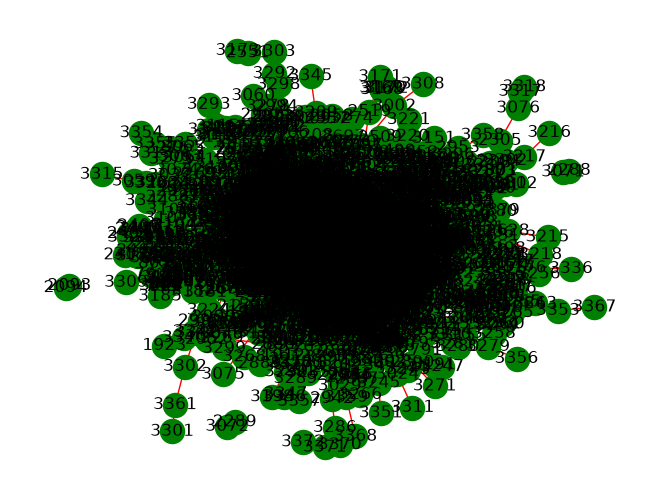

In [40]:
pos = nx.spring_layout(G, k=3.0, seed=42)
nx.draw(G, pos=pos, with_labels=True, node_color='green', edge_color='red')

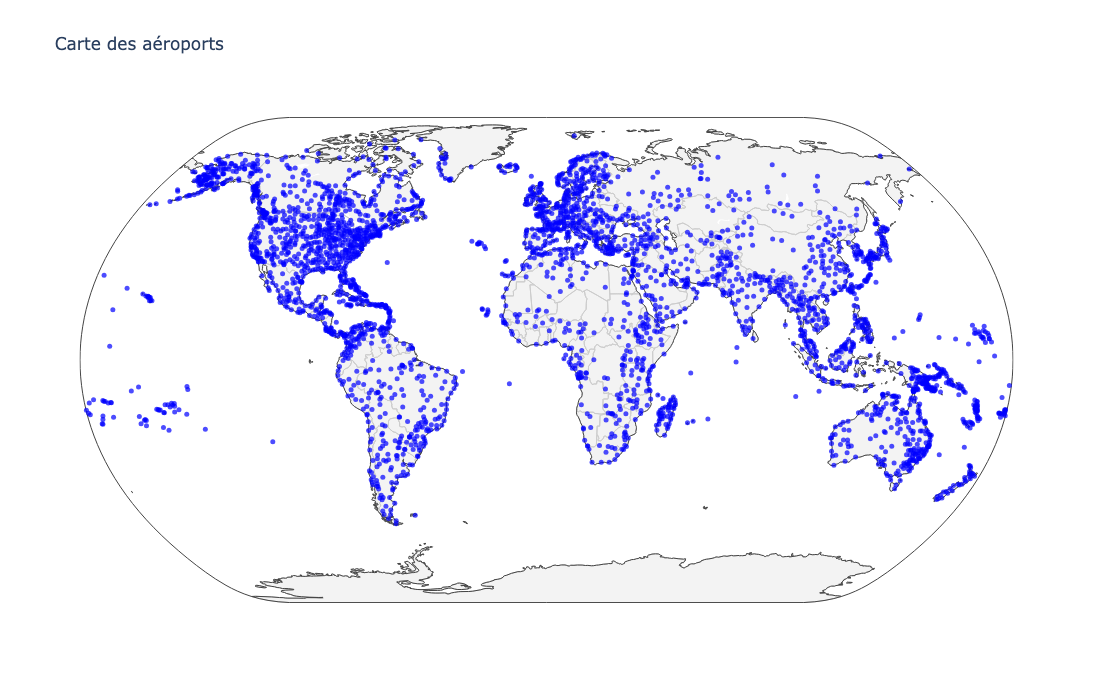

In [41]:
# Récupération des coordonnées depuis les attributs des nœuds
lons = [data['lon'] for _, data in G.nodes(data=True)]
lats = [data['lat'] for _, data in G.nodes(data=True)]

# Textes survolés (ex: nom de ville et pays)
textes = [
    f"{data['city_name']}, {data['country']}<br>Population: {data['population']}"
    for _, data in G.nodes(data=True)
]

# Création de la trace des nœuds
node_trace = go.Scattergeo(
    lon=lons,
    lat=lats,
    text=textes,
    mode='markers',
    marker=dict(
        size=5,
        color='blue',
        opacity=0.7
    ),
    hoverinfo='text'
)

# Assemblage de la figure
fig = go.Figure(data=[node_trace])
fig.update_layout(
    title='Carte des aéroports',
    geo=dict(
        projection_type='natural earth',  # ou 'equirectangular', 'orthographic', etc.
        showland=True,
        landcolor='rgb(243, 243, 243)',
        showcountries=True,
        countrycolor='rgb(204, 204, 204)'
    ),
    height=700
)
fig.show()

Pour la suite, nous décidons de prédire le pays en fonction des coordonnées géographiques.

Objectif : entraîner un GCN à prédire le pays (country) d'une ville à partir de : ses features (coordonnées lon, lat, éventuellement population), et de la structure du graphe (relations entre villes).

Les villes du même pays ont tendance à être proches géographiquement et connectées entre elles.

In [58]:
data = from_networkx(
    G,
    group_node_attrs=["lon", "lat", "population"],
)
print(data)

Data(edge_index=[2, 27094], country=[3363], city_name=[3363], x=[3363, 3])


In [53]:
comptage = Counter(data.country)

for pays, nb in comptage.most_common():
    print(f"{pays}: {nb}")

total = sum(comptage.values())
print(f"\nTotal: {total} lignes (attendu : {G.number_of_nodes()})")

USA: 650
CANADA: 243
AUSTRALIA: 207
BRAZIL: 105
CHINA: 93
PAPUA_NEW_GUINEA: 92
RUSSIA: 70
JAPAN: 69
M&Eacute;XICO#MEXICO: 59
ARGENTINA: 57
INDIA: 57
FRANCE: 56
INDONESIA: 47
NORWAY: 46
COLOMBIA: 42
UNITED_KINGDOM: 40
MADAGASCAR: 40
PHILIPPINES: 34
MALAYSIA: 33
SWEDEN: 33
GREECE: 33
SPAIN: 32
ITALY: 31
PAKISTAN: 31
NEW_ZEALAND: 28
GERMANY: 28
VENEZUELA: 28
VANUATU: 27
DENMARK: 27
ETHIOPIA: 27
ALGERIA: 27
SAUDI_ARABIA: 26
TURKEY: 25
THAILAND: 24
IRAN: 22
BAHAMAS: 22
FRENCH_POLYNESIA: 21
FINLAND: 21
SOUTH_AFRICA: 21
MYANMAR: 21
MARSHALL_ISLANDS: 20
CHILE: 17
PER&Uacute;#PERU: 17
FIJI: 16
UKRAINE: 16
SOLOMON_ISLANDS: 15
TANZANIA: 15
SOUTH_KOREA: 14
PANAMA: 13
CUBA: 13
ROMANIA: 13
PORTUGAL: 13
CONGO,_DEMOCRATIC_PEOPLES'S_REPUBLIC: 13
SUDAN: 13
VI&Ecirc;T_NAM#VIET_NAM,VIETNAM: 12
COSTA_RICA: 12
MOROCCO: 12
ICELAND: 12
TAIWAN: 11
BOLIVIA: 11
HONDURAS: 11
KENYA: 11
NEW_CALEDONIA: 10
NEPAL: 10
KAZAKHSTAN: 10
GABON: 10
ZAMBIA: 10
EGYPT: 9
UZBEKHISTAN: 9
POLAND: 9
MOZAMBIQUE: 9
NIGERIA: 9
YEMEN: 

In [54]:
counts = np.array(list(comptage.values()))
print(f"Max: {counts.max()}, Min: {counts.min()}")
print(f"Ratio déséquilibre: {counts.max()/counts.min():.0f}:1")
print(f"Médiane: {np.median(counts)}, Moyenne: {counts.mean():.1f}")
print(f"Pays avec <3 nœuds: {(counts<3).sum()} / {len(counts)}")

Max: 650, Min: 1
Ratio déséquilibre: 650:1
Médiane: 4.0, Moyenne: 15.9
Pays avec <3 nœuds: 86 / 212


In [55]:
# Récupérer les labels (dans l'ordre des nœuds du graphe)
labels_str = [d['country'] for _, d in G.nodes(data=True)]

# Mapping
classes = sorted(set(labels_str))
pays2idx = {p: i for i, p in enumerate(classes)}
idx2pays = {i: p for p, i in pays2idx.items()}

y = torch.tensor([pays2idx[p] for p in labels_str], dtype=torch.long)
print(f"Nombre de classes : {len(classes)}")
print(f"Nombre de nœuds : {len(y)}")

Nombre de classes : 212
Nombre de nœuds : 3363


Comment traiter les pays avec une seule présence?
Les garder tels qu'ils sont?
Les grouper? Par nombre de population? Par région?

In [59]:
# ============================================================
# 1. Normaliser les features
# ============================================================
mean = data.x.mean(dim=0, keepdim=True)
std  = data.x.std(dim=0, keepdim=True) + 1e-9
data.x = (data.x - mean) / std

# ============================================================
# 2. Extraire les labels (country)
# ============================================================
nodes = list(G.nodes(data=True))
countries = [d['country'] for _, d in nodes]

le = LabelEncoder()
data.y = th.tensor(le.fit_transform(countries), dtype=th.long)

# ============================================================
# 3. Filtrer : ne garder que les classes avec >= MIN_COUNT exemples
# ============================================================
MIN_COUNT = 5   # ⚠️ doit être >= 3 pour garantir >=1 par split

unique, counts = np.unique(data.y.numpy(), return_counts=True)
keep_classes = unique[counts >= MIN_COUNT]
print(f"Classes avant filtrage : {len(unique)}")
print(f"Classes gardées        : {len(keep_classes)}")

# Masque sur les nœuds à garder
node_mask = th.isin(data.y, th.tensor(keep_classes))
print(f"Nœuds avant : {data.num_nodes} | Nœuds gardés : {node_mask.sum().item()}")

# ============================================================
# 4. Réindexation dense des labels 0..K-1
# ============================================================
label_map = th.full((int(data.y.max().item()) + 1,), -1, dtype=th.long)
label_map[th.tensor(keep_classes)] = th.arange(len(keep_classes))
new_y = label_map[data.y[node_mask]]

# Filtrer les features
new_x = data.x[node_mask]

# ============================================================
# 5. Filtrer les arêtes : garder celles dont LES DEUX extrémités sont gardées
# ============================================================
old_to_new = th.full((data.num_nodes,), -1, dtype=th.long)
old_to_new[node_mask] = th.arange(node_mask.sum().item())

edge_mask = node_mask[data.edge_index[0]] & node_mask[data.edge_index[1]]
new_edge_index = old_to_new[data.edge_index[:, edge_mask]]

print(f"Arêtes avant : {data.edge_index.shape[1]} | Arêtes gardées : {new_edge_index.shape[1]}")

# ============================================================
# 6. Redistribution dans un nouveau Data
# ============================================================
data = Data(x=new_x, edge_index=new_edge_index, y=new_y)
print(f"\n{data}")
print(f"Classes finales : {data.y.max().item() + 1}")

# ============================================================
# 7. SPLIT STRATIFIÉ GARANTI : >=1 exemple par classe dans train/val/test
# ============================================================
num_nodes   = data.num_nodes
num_classes = int(data.y.max().item()) + 1
y_np        = data.y.numpy()

rng = np.random.default_rng(42)

train_idx, val_idx, test_idx = [], [], []
for c in range(num_classes):
    idx_c = np.where(y_np == c)[0]
    rng.shuffle(idx_c)
    n = len(idx_c)

    # Répartition proportionnelle 70/15/15 avec minimum 1 partout
    n_val_c  = max(1, int(round(0.15 * n)))
    n_test_c = max(1, int(round(0.15 * n)))
    n_train_c = n - n_val_c - n_test_c

    # Sécurité si la classe est trop petite (n < 3)
    if n_train_c < 1:
        n_train_c = 1
        remaining = n - 1
        n_val_c  = max(1, remaining // 2)
        n_test_c = remaining - n_val_c
        if n_test_c < 1:   # cas n == 2 (ne devrait pas arriver si MIN_COUNT>=3)
            n_test_c = 1
            n_val_c  = n - n_train_c - n_test_c

    train_idx.extend(idx_c[:n_train_c])
    val_idx.extend(idx_c[n_train_c:n_train_c + n_val_c])
    test_idx.extend(idx_c[n_train_c + n_val_c:])

data.train_mask = th.zeros(num_nodes, dtype=th.bool)
data.val_mask   = th.zeros(num_nodes, dtype=th.bool)
data.test_mask  = th.zeros(num_nodes, dtype=th.bool)
data.train_mask[train_idx] = True
data.val_mask[val_idx]     = True
data.test_mask[test_idx]   = True

# ============================================================
# 8. VÉRIFICATION : chaque classe présente dans chaque split
# ============================================================
print("\n--- Vérification par classe ---")
ok = True
for c in range(num_classes):
    tr = (data.y[data.train_mask] == c).sum().item()
    va = (data.y[data.val_mask]   == c).sum().item()
    te = (data.y[data.test_mask]  == c).sum().item()
    if tr < 1 or va < 1 or te < 1:
        ok = False
        print(f"❌ Classe {c}: train={tr} val={va} test={te}")
assert ok, "Certaines classes sont absentes d'un split !"
print("✅ Chaque classe est présente dans train / val / test")

# ============================================================
# 9. Affichage final
# ============================================================
print(f"\nNum nodes  : {data.num_nodes}")
print(f"Num edges  : {data.edge_index.shape[1]}")
print(f"Num classes: {num_classes}")
print(f"Train/Val/Test : {data.train_mask.sum().item()}/{data.val_mask.sum().item()}/{data.test_mask.sum().item()}")

# Distribution des classes restantes (global)
unique, counts = np.unique(data.y.numpy(), return_counts=True)
print(f"Min/Max/Médiane exemples par classe : {counts.min()}/{counts.max()}/{int(np.median(counts))}")

# Distribution par split (utile pour repérer les classes rares)
for name, mask in [("train", data.train_mask),
                   ("val",   data.val_mask),
                   ("test",  data.test_mask)]:
    _, cnt = np.unique(data.y[mask].numpy(), return_counts=True)
    print(f"{name:5s} → min/max par classe : {cnt.min()}/{cnt.max()}")

Classes avant filtrage : 212
Classes gardées        : 99
Nœuds avant : 3363 | Nœuds gardés : 3160
Arêtes avant : 27094 | Arêtes gardées : 23344

Data(x=[3160, 3], edge_index=[2, 23344], y=[3160])
Classes finales : 99

--- Vérification par classe ---
✅ Chaque classe est présente dans train / val / test

Num nodes  : 3160
Num edges  : 23344
Num classes: 99
Train/Val/Test : 2204/478/478
Min/Max/Médiane exemples par classe : 5/650/13
train → min/max par classe : 3/454
val   → min/max par classe : 1/98
test  → min/max par classe : 1/98


In [60]:
class Model(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels=3):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

def train(data, model, epochs):
    optimizer = th.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    model.train()

    train_losses, val_losses = [], []
    train_accs,   val_accs   = [], []

    for epoch in range(epochs):
        # --- Entraînement (train) ---
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.nll_loss(out[data.train_mask], data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        # --- Évaluation sur val (sans gradient, sans dropout) ---
        model.eval()
        with th.no_grad():
            out_eval = model(data.x, data.edge_index)
            val_loss = F.nll_loss(out_eval[data.val_mask], data.y[data.val_mask])
        model.train()

        # --- Stockage ---
        train_losses.append(loss.item())
        val_losses.append(val_loss.item())

        train_acc = (out[data.train_mask].argmax(1) == data.y[data.train_mask]).float().mean().item()
        val_acc   = (out_eval[data.val_mask].argmax(1) == data.y[data.val_mask]).float().mean().item()
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        if epoch % 20 == 0:
            print(f"Epoch {epoch:03d} | "
                  f"Train loss: {loss.item():.4f}, acc: {train_acc:.3f} | "
                  f"Val loss: {val_loss.item():.4f}, acc: {val_acc:.3f}")

    return model, train_losses, val_losses, train_accs, val_accs

In [50]:
def test(data, model):
    model.eval()
    with th.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=1)
    acc_train = (pred[data.train_mask] == data.y[data.train_mask]).float().mean().item()
    acc_val   = (pred[data.val_mask]   == data.y[data.val_mask]).float().mean().item()
    acc_test  = (pred[data.test_mask]  == data.y[data.test_mask]).float().mean().item()
    print(f"Train acc: {acc_train:.4f} | Val acc: {acc_val:.4f} | Test acc: {acc_test:.4f}")
    return acc_test

In [61]:
num_classes = int(data.y.max().item() + 1)
print(f"Nombre de classes : {num_classes}")

Nombre de classes : 99


in_channels=3 | out_channels=99
Epoch 000 | Train loss: 4.5890, acc: 0.066 | Val loss: 4.5430, acc: 0.153
Epoch 020 | Train loss: 3.4608, acc: 0.314 | Val loss: 3.3702, acc: 0.335
Epoch 040 | Train loss: 2.7554, acc: 0.341 | Val loss: 2.7011, acc: 0.333
Epoch 060 | Train loss: 2.4560, acc: 0.373 | Val loss: 2.3910, acc: 0.360
Epoch 080 | Train loss: 2.2498, acc: 0.403 | Val loss: 2.1782, acc: 0.414
Epoch 100 | Train loss: 2.1182, acc: 0.439 | Val loss: 2.0349, acc: 0.473
Epoch 120 | Train loss: 2.0363, acc: 0.462 | Val loss: 1.9306, acc: 0.494
Epoch 140 | Train loss: 1.9591, acc: 0.480 | Val loss: 1.8563, acc: 0.519
Epoch 160 | Train loss: 1.8965, acc: 0.487 | Val loss: 1.7983, acc: 0.531
Epoch 180 | Train loss: 1.8509, acc: 0.496 | Val loss: 1.7587, acc: 0.542
Epoch 200 | Train loss: 1.8236, acc: 0.508 | Val loss: 1.7293, acc: 0.542
Epoch 220 | Train loss: 1.7649, acc: 0.525 | Val loss: 1.6932, acc: 0.550
Epoch 240 | Train loss: 1.7651, acc: 0.512 | Val loss: 1.6714, acc: 0.563
Epoch 

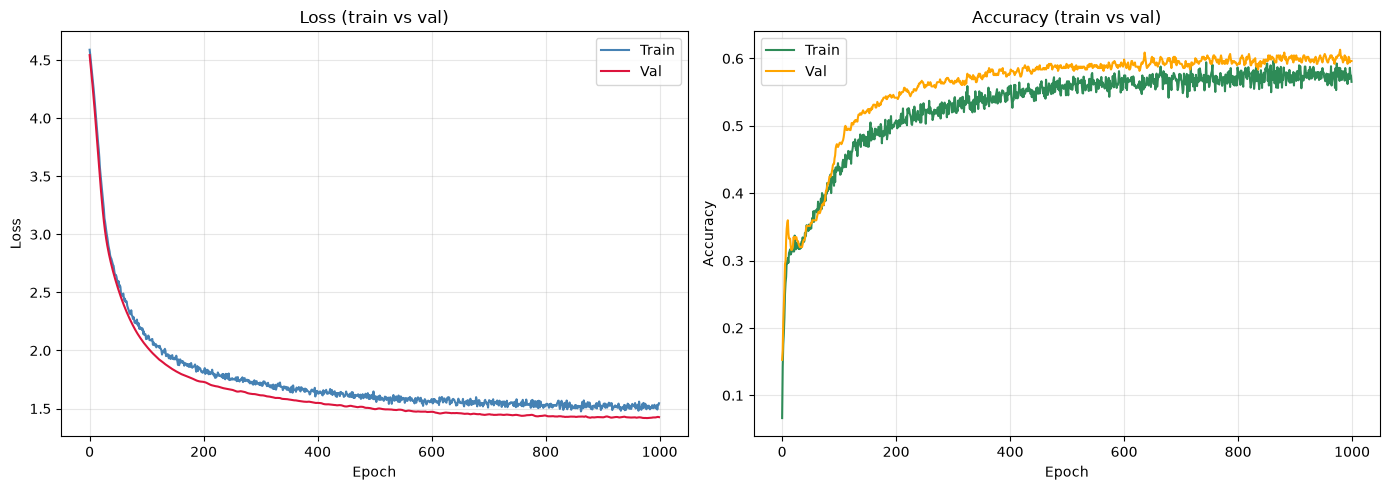

In [62]:
# --- Définir in_channels et out_channels dynamiquement ---
in_channels  = data.x.shape[1]
out_channels = int(data.y.max().item() + 1)

print(f"in_channels={in_channels} | out_channels={out_channels}")

# --- Instancier ---
model = Model(in_channels=in_channels, hidden_channels=16, out_channels=out_channels)

# --- Entraîner (capturer les 5 retours) ---
model, train_losses, val_losses, train_accs, val_accs = train(data, model, epochs=1000)

# --- Évaluer sur le test set (une seule fois, à la fin) ---
pred = test(data, model)

# --- Tracer : loss (train vs val) + accuracy (train vs val) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss : train vs val
axes[0].plot(train_losses, label="Train", color="steelblue")
axes[0].plot(val_losses,   label="Val",   color="crimson")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss (train vs val)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Accuracy : train vs val
axes[1].plot(train_accs, label="Train", color="seagreen")
axes[1].plot(val_accs,   label="Val",   color="orange")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Accuracy (train vs val)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()